# Phân Loại 37 Giống Chó Mèo với Dual-Stream EfficientNet-B0 (From Scratch)

**Thông Tin Chung**
* **Sinh viên thực hiện:** Nguyễn Hữu Hoàng Luân
* **Mô hình:** Dual-Stream EfficientNet-B0 (Face + Body Zoom kết hợp Gated Fusion Neck)
* **Phương thức huấn luyện:** From Scratch (100% không sử dụng pre-trained weights, khởi tạo Kaiming Normal)
* **Tập dữ liệu:** Oxford-IIIT Pet kết hợp New Dataset mở rộng (37 giống loài: 12 giống mèo, 25 giống chó)
  * Tập Huấn luyện mở rộng (Trainset): 9.301 ảnh (3.680 ảnh Oxford-IIIT Pet Trainval + 5.621 ảnh New Dataset đã lọc sạch bằng CLIP)
  * Tập Benchmark Test: 3.669 ảnh chuẩn Oxford-IIIT Pet (đảm bảo đối sánh khách quan 1-1)

**Yêu Cầu Kỹ Thuật & Chuẩn Đối Sánh**
* **Kích thước đầu vào:** 288 × 288 × 3 cho mỗi luồng (Body Stream: 288×288 + Head Zoom Stream: 288×288)
* **Tiền xử lý Data-Centric:** Cắt trích xuất tiền cảnh (Foreground BBox Crop) và trung hòa phông nền (RGB: 128, 128, 128) từ Trimap.
* **Chiến lược tăng cường dữ liệu:**
  * Part-Level Crop: Cắt ngẫu nhiên 8% – 40% diện tích (tai, chân, đuôi, thân), ép mô hình học đặc trưng cục bộ.
  * Tăng cường kết cấu: CLAHE trên kênh L (không gian màu LAB), Bilateral Filtering, Random Erasing.
* **Chiến lược tối ưu hóa:** AdamW (LR: 5e-4, Weight Decay: 1e-2), Cosine Annealing LR Scheduler, Label Smoothing 0.05, Batch Size 32, 100 Epochs.

In [1]:
# [Môi trường Kaggle / Colab] Tự động tải mã nguồn từ GitHub và kết nối Google Drive
import os
import subprocess

# 1. Kết nối Google Drive trên Colab để Checkpoint được lưu vĩnh viễn (chống mất mát khi ngắt kết nối)
if os.path.exists("/content"):
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        print(">> Đã kết nối Google Drive thành công! Checkpoints sẽ được lưu trực tiếp vào Drive.")
    except Exception as e:
        print(f">> Bỏ qua mount Google Drive ({e}).")

# 2. Tải repository từ GitHub
if os.path.exists("/kaggle") or os.path.exists("/content"):
    REPO_URL = "https://github.com/LuanNguyen23T/ml-semester-cat-dog-classifier.git"
    TARGET_DIR = "/kaggle/working/ml-semester-cat-dog-classifier" if os.path.exists("/kaggle") else "/content/ml-semester-cat-dog-classifier"
    
    if not os.path.exists(TARGET_DIR):
        print(f">> Đang tải repository từ {REPO_URL}...")
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, TARGET_DIR], check=True)
        print(f">> Tải thành công repository vào {TARGET_DIR}")
    else:
        print(f">> Repository đã tồn tại tại {TARGET_DIR}")
        try:
            subprocess.run(["git", "-C", TARGET_DIR, "pull"], check=False)
        except Exception:
            pass
        
    # Di chuyển vào thư mục notebook tương ứng
    NOTEBOOK_DIR = os.path.join(TARGET_DIR, "notebooks", "Hoang_Luan", "16_dual_stream_efficientnet")
    if os.path.exists(NOTEBOOK_DIR):
        os.chdir(NOTEBOOK_DIR)
    else:
        os.chdir(TARGET_DIR)
    print(f">> Thư mục làm việc hiện tại: {os.getcwd()}")
else:
    print(f">> Chạy môi trường Local: {os.getcwd()}")


>> Bỏ qua mount Google Drive (Mounting drive is unsupported in this environment. Use PyDrive2 instead. See examples at https://colab.research.google.com/notebooks/io.ipynb#scrollTo=7taylj9wpsA2.).
>> Đang tải repository từ https://github.com/LuanNguyen23T/ml-semester-cat-dog-classifier.git...


Cloning into '/kaggle/working/ml-semester-cat-dog-classifier'...


>> Tải thành công repository vào /kaggle/working/ml-semester-cat-dog-classifier
>> Thư mục làm việc hiện tại: /kaggle/working/ml-semester-cat-dog-classifier/notebooks/Hoang_Luan/16_dual_stream_efficientnet


## Bước 1: Khởi tạo Thư viện & Thiết lập Phần cứng (CUDA / MPS / CPU)
* Nạp các thư viện cốt lõi: PyTorch, Torchvision, OpenCV, Scikit-learn, Matplotlib.
* Tự động nhận diện thiết bị tính toán (`cuda`, `mps` hoặc `cpu`) và cố định Random Seed (42) đảm bảo tính tái lập.

In [2]:
import os
import sys
import json
import random
import argparse
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, classification_report

current_dir = Path(os.getcwd())
possible_roots = [
    current_dir,
    current_dir.parent,
    current_dir.parent.parent,
    current_dir.parent.parent.parent,
    Path("/kaggle/working/ml-semester-cat-dog-classifier"),
    Path("/content/ml-semester-cat-dog-classifier")
]
project_root = None
for r in possible_roots:
    if (r / "src").exists() and (r / "src" / "dataset.py").exists():
        project_root = r.resolve()
        break

if project_root and str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
    print(f">> Đã nhận diện Project Root tại: {project_root}")

# Kiểm tra tăng tốc phần cứng: Ưu tiên CUDA (NVIDIA GPU trên Kaggle/Colab) hoặc MPS (Apple Silicon)
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f">> Khởi tạo thiết bị thành công: NVIDIA CUDA ({torch.cuda.get_device_name(0)})")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print(f">> Khởi tạo thiết bị thành công: Apple Silicon MPS (Metal Performance Shaders)")
else:
    device = torch.device("cpu")
    print(f">> Khởi tạo thiết bị: CPU")

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)


>> Đã nhận diện Project Root tại: /kaggle/working/ml-semester-cat-dog-classifier
>> Khởi tạo thiết bị thành công: NVIDIA CUDA (Tesla T4)


## Bước 2: Thiết lập Siêu tham số & Định vị Tự động Cả 2 Dataset (Argparse)
* Thiết lập các siêu tham số chuẩn hóa: Image Size 288×288, Batch Size 32, 100 Epochs, Learning Rate 0.0005.
* Tự động quét và nạp cả 2 tập dữ liệu (Oxford-IIIT Pet và New Dataset) trên Local, Kaggle hoặc Google Drive; định tuyến thư mục lưu trữ độc lập: `./checkpoints` và `./plots`.

In [3]:
def find_dataset_paths():
    """Tự động tìm kiếm đường dẫn cho CẢ 2 tập dữ liệu trên Kaggle, Colab hoặc Local."""
    oxford_dir = None
    new_dataset_dir = None
    
    # 0. Nếu trên Colab: Kiểm tra và giải nén nhanh nếu có file zip trong Google Drive
    if os.path.exists("/content/drive/MyDrive"):
        drive_root = "/content/drive/MyDrive"
        # Tự động giải nén zip sang ổ SSD /content/data (nhanh hơn đọc trực tiếp qua Drive 10-20 lần)
        os.makedirs("/content/data", exist_ok=True)
        for root, dirs, files in os.walk(drive_root):
            for f in files:
                if f.endswith(".zip") and ("oxford" in f.lower() or "pet" in f.lower()):
                    zip_p = os.path.join(root, f)
                    if "new" in f.lower() and not os.path.exists("/content/data/new_dataset"):
                        print(f">> Giải nén nhanh {f} từ Drive sang /content/data/new_dataset...")
                        os.system(f"unzip -q '{zip_p}' -d /content/data/")
                    elif not os.path.exists("/content/data/oxford-iiit-pet"):
                        print(f">> Giải nén nhanh {f} từ Drive sang /content/data/oxford-iiit-pet...")
                        os.system(f"unzip -q '{zip_p}' -d /content/data/")

    # 1. Tìm trên Kaggle /kaggle/input
    kaggle_input = "/kaggle/input"
    if os.path.exists(kaggle_input):
        input_items = os.listdir(kaggle_input)
        print(f">> Danh sách thư mục trong /kaggle/input: {input_items}")
        for root, dirs, files in os.walk(kaggle_input):
            if "images" in dirs and os.path.exists(os.path.join(root, "annotations", "trainval.txt")):
                lower_path = root.lower()
                has_trimaps = os.path.exists(os.path.join(root, "annotations", "trimaps"))
                if "new" in lower_path or "augment" in lower_path:
                    new_dataset_dir = root
                elif has_trimaps or ("oxford" in lower_path and "new" not in lower_path):
                    oxford_dir = root
                else:
                    if new_dataset_dir is None:
                        new_dataset_dir = root
    
    # 2. Tìm trên Google Colab /content/data hoặc /content
    candidates_colab = [
        ("/content/data/oxford-iiit-pet", "/content/data/new_dataset"),
        ("/content/oxford-iiit-pet", "/content/new_dataset"),
        ("/content/ml-semester-cat-dog-classifier/dataset/oxford-iiit-pet", "/content/ml-semester-cat-dog-classifier/dataset/new_dataset")
    ]
    for ox_c, new_c in candidates_colab:
        if oxford_dir is None and os.path.exists(os.path.join(ox_c, "annotations", "trainval.txt")):
            oxford_dir = ox_c
        if new_dataset_dir is None and os.path.exists(os.path.join(new_c, "annotations", "trainval.txt")):
            new_dataset_dir = new_c

    # 2.1 Tải qua kagglehub nếu chưa thấy New Dataset (hỗ trợ cả Kaggle và Colab)
    if new_dataset_dir is None and (os.path.exists("/kaggle") or os.path.exists("/content")):
        try:
            import kagglehub
            print(">> Thử tải tự động oxford-pet-new-dataset qua kagglehub...")
            dl_new = kagglehub.dataset_download("nguyenhuuhoangluan/oxford-pet-new-dataset")
            for root, dirs, files in os.walk(dl_new):
                if "images" in dirs and os.path.exists(os.path.join(root, "annotations", "trainval.txt")):
                    new_dataset_dir = root
                    print(f">> Nạp thành công New Dataset qua kagglehub: {new_dataset_dir}")
                    break
        except Exception as e:
            print(f">> Không thể tải qua kagglehub ({e}).")

    # 3. Tìm trên thư mục cục bộ Local
    if oxford_dir is None:
        candidates_oxford = [
            "../../../dataset/oxford-iiit-pet",
            "../../dataset/oxford-iiit-pet",
            str(project_root / "dataset" / "oxford-iiit-pet") if project_root else "",
            "dataset/oxford-iiit-pet"
        ]
        for c in candidates_oxford:
            if c and os.path.exists(os.path.join(c, "annotations", "trainval.txt")):
                oxford_dir = c
                break
                
    if new_dataset_dir is None:
        candidates_new = [
            "../../../dataset/new_dataset",
            "../../dataset/new_dataset",
            str(project_root / "dataset" / "new_dataset") if project_root else "",
            "dataset/new_dataset"
        ]
        for c in candidates_new:
            if c and os.path.exists(os.path.join(c, "annotations", "trainval.txt")):
                new_dataset_dir = c
                break
                
    # 4. Nạp Oxford-IIIT Pet qua torchvision nếu chạy cloud mà thiếu
    if oxford_dir is None and (os.path.exists("/kaggle") or os.path.exists("/content")):
        print(">> Không tìm thấy Oxford-IIIT Pet trong input, đang tự động nạp qua torchvision...")
        import torchvision
        dl_root = "/kaggle/working/data" if os.path.exists("/kaggle") else "/content/data"
        torchvision.datasets.OxfordIIITPet(root=dl_root, split="trainval", download=True)
        oxford_dir = os.path.join(dl_root, "oxford-iiit-pet")
        
    return oxford_dir, new_dataset_dir

def parse_args():
    parser = argparse.ArgumentParser(description="Dual-Stream EfficientNet-B0 (Face + Body Zoom) 100% Pure From Scratch")
    oxford_path, new_path = find_dataset_paths()
    parser.add_argument("--oxford_dir", type=str, default=oxford_path, help="Đường dẫn tập Oxford-IIIT Pet gốc")
    parser.add_argument("--new_dataset_dir", type=str, default=new_path, help="Đường dẫn tập New Dataset")
    parser.add_argument("--task", type=str, default="breed", choices=["breed"])
    parser.add_argument("--img_size", type=int, default=288, help="Kích thước ảnh 288x288 giữ trọn vẹn đặc trưng vi mô")
    parser.add_argument("--batch_size", type=int, default=32, help="Mini-batch size (32 hoặc 48 tối ưu trên GPU)")
    parser.add_argument("--epochs", type=int, default=100, help="Số epochs huấn luyện 100")
    parser.add_argument("--lr", type=float, default=5e-4, help="Learning rate 0.0005 chuẩn cho AdamW From Scratch")
    parser.add_argument("--weight_decay", type=float, default=1e-2, help="Decoupled weight decay 0.01 chống overfitting")
    parser.add_argument("--label_smoothing", type=float, default=0.05, help="Label smoothing nhẹ 0.05 phân định rõ 37 lớp")
    parser.add_argument("--crop_foreground", type=bool, default=True, help="Tự động cắt chặt Bounding Box vùng thú cưng")
    parser.add_argument("--remove_background", type=bool, default=True, help="Xóa nền thành màu xám trung tính (128, 128, 128)")
    
    # Thiết lập đường dẫn Checkpoints: Ưu tiên Google Drive trên Colab để không bao giờ bị xóa khi mất kết nối
    default_ckpt_dir = "./checkpoints"
    default_plots_dir = "./plots"
    if os.path.exists("/content/drive/MyDrive"):
        default_ckpt_dir = "/content/drive/MyDrive/OxfordPet_Checkpoints/16_dual_stream/checkpoints"
        default_plots_dir = "/content/drive/MyDrive/OxfordPet_Checkpoints/16_dual_stream/plots"
        print(f">> Google Drive khả dụng! Checkpoints sẽ được lưu trữ an toàn tại: {default_ckpt_dir}")
        
    parser.add_argument("--checkpoint_dir", type=str, default=default_ckpt_dir)
    parser.add_argument("--plots_dir", type=str, default=default_plots_dir)
    try:
        args, _ = parser.parse_known_args()
    except:
        args = parser.parse_args([])
    return args

args = parse_args()
print(f"[1] Thư mục Oxford Base: {args.oxford_dir}")
print(f"[2] Thư mục New Dataset: {args.new_dataset_dir}")
print(f"[3] Thư mục lưu Checkpoint: {args.checkpoint_dir}")
print(f"Cấu hình Dual-Stream EffNet: Resolution = {args.img_size}x{args.img_size} | Batch size = {args.batch_size} | Epochs = {args.epochs} | LR = {args.lr} | Device = {device}")


>> Danh sách thư mục trong /kaggle/input: ['datasets']
>> Không tìm thấy Oxford-IIIT Pet trong input, đang tự động nạp qua torchvision...


100%|██████████| 792M/792M [00:21<00:00, 36.6MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 16.1MB/s]


[1] Thư mục Oxford Base: /kaggle/working/data/oxford-iiit-pet
[2] Thư mục New Dataset: /kaggle/input/datasets/nguyenhuuhoangluan/oxford-pet-new-dataset/new_dataset
[3] Thư mục lưu Checkpoint: ./checkpoints
Cấu hình Dual-Stream EffNet: Resolution = 288x288 | Batch size = 32 | Epochs = 100 | LR = 0.0005 | Device = cuda


## Bước 3: Nạp Dữ liệu Dual-Stream 2 Luồng (Body View & Head Zoom View)
* **Luồng Thân (Body View):** Trích xuất toàn thân thú cưng kết hợp loại bỏ nền nhiễu bằng màu xám trung tính (128, 128, 128).
* **Luồng Mặt (Head Zoom View):** Trích xuất cận cảnh siêu độ phân giải vùng đầu/khuôn mặt từ Bounding Box XML.
* **Tập Huấn luyện (Trainset):** 9.301 ảnh (3.680 ảnh Oxford Trainval + 5.621 ảnh New Dataset đã lọc sạch bằng CLIP).
* **Tập Kiểm thử (Testset):** Đúng 3.669 ảnh chuẩn Oxford-IIIT Pet nhằm đối sánh khách quan 1-1 với benchmark quốc tế.

In [4]:
from PIL import Image
import torchvision.transforms.functional as TF
from torch.utils.data import ConcatDataset, DataLoader
from src.dataset import OxfordPetDualStreamDataset, get_transforms

train_transform = get_transforms(img_size=args.img_size, is_train=True, use_part_aug=True, use_clahe=True)
test_transform = get_transforms(img_size=args.img_size, is_train=False)

train_list = []
classes = None

# 1. Nạp Dataset 1: Oxford-IIIT Pet Gốc (Trainval = 3.680 | Benchmark Test = 3.669)
if args.oxford_dir and os.path.exists(args.oxford_dir):
    ox_train = OxfordPetDualStreamDataset(
        root_dir=args.oxford_dir, split="trainval", task=args.task,
        transform=train_transform, crop_foreground=args.crop_foreground, remove_background=args.remove_background
    )
    ox_test = OxfordPetDualStreamDataset(
        root_dir=args.oxford_dir, split="test", task=args.task,
        transform=test_transform, crop_foreground=args.crop_foreground, remove_background=args.remove_background
    )
    train_list.append(ox_train)
    classes = ox_train.class_names
    print(f">> Đã nạp Oxford Base Dataset (Dual-Stream): Trainval = {len(ox_train)} | Test = {len(ox_test)}")

# 2. Nạp TOÀN BỘ Dataset Mới vào Tập Train (Gộp cả trainval + test = 5.621 ảnh đã lọc sạch)
if args.new_dataset_dir and os.path.exists(args.new_dataset_dir):
    new_part1 = OxfordPetDualStreamDataset(
        root_dir=args.new_dataset_dir, split="trainval", task=args.task,
        transform=train_transform, crop_foreground=False, remove_background=False
    )
    new_part2 = OxfordPetDualStreamDataset(
        root_dir=args.new_dataset_dir, split="test", task=args.task,
        transform=train_transform, crop_foreground=False, remove_background=False
    )
    train_list.append(new_part1)
    train_list.append(new_part2)
    if classes is None:
        classes = new_part1.class_names
    print(f">> Đã nạp TOÀN BỘ New Dataset vào Huấn luyện (Dual-Stream): {len(new_part1) + len(new_part2)} ảnh ({len(new_part1)} trainval + {len(new_part2)} test)")

# 3. Thiết lập Trainset Mở Rộng và Testset Benchmark Chuẩn
trainset = ConcatDataset(train_list) if len(train_list) > 1 else train_list[0]
testset = ox_test  # Đánh giá trực tiếp trên đúng 3.669 ảnh chuẩn Oxford
num_classes = len(classes)

# Thiết lập num_workers linh hoạt: 2 cho CUDA (Kaggle/Colab) hoặc 0 cho MPS (macOS tránh nghẽn luồng)
num_workers = 2 if device.type == "cuda" else 0
trainloader = DataLoader(trainset, batch_size=args.batch_size, shuffle=True, num_workers=num_workers, pin_memory=(device.type == "cuda"))
testloader = DataLoader(testset, batch_size=args.batch_size, shuffle=False, num_workers=num_workers, pin_memory=(device.type == "cuda"))

print(f"\n==================================================================")
print(f">> KHỞI TẠO THÀNH CÔNG HỆ THỐNG DỮ LIỆU DUAL-STREAM 2 LUỒNG:")
print(f"- Tổng số mẫu huấn luyện mở rộng (Expanded Train): {len(trainset)} ảnh (3.680 Oxford + 5.621 Mới)")
print(f"- Tổng số mẫu kiểm thử Benchmark Chuẩn (Canonical Test): {len(testset)} ảnh (100% Oxford-IIIT Pet)")
print(f"- Mỗi mẫu chứa 2 luồng: [Body Tensor 288x288] + [Head Zoom Tensor 288x288]")
print(f"- Số lượng giống loài phân loại: {num_classes} giống")
print(f"==================================================================\n")


>> Đã nạp Oxford Base Dataset (Dual-Stream): Trainval = 3680 | Test = 3669
>> Đã nạp TOÀN BỘ New Dataset vào Huấn luyện (Dual-Stream): 5621 ảnh (4511 trainval + 1110 test)

>> KHỞI TẠO THÀNH CÔNG HỆ THỐNG DỮ LIỆU DUAL-STREAM 2 LUỒNG:
- Tổng số mẫu huấn luyện mở rộng (Expanded Train): 9301 ảnh (3.680 Oxford + 5.621 Mới)
- Tổng số mẫu kiểm thử Benchmark Chuẩn (Canonical Test): 3669 ảnh (100% Oxford-IIIT Pet)
- Mỗi mẫu chứa 2 luồng: [Body Tensor 288x288] + [Head Zoom Tensor 288x288]
- Số lượng giống loài phân loại: 37 giống



## Bước 4: Khởi tạo Kiến trúc Dual-Stream EfficientNet-B0 (From Scratch)
* **Siamese MBConv Backbone:** Chia sẻ trọng số giữa luồng Thân và Mặt, tối ưu hóa ~5.08M tham số ngẫu nhiên theo phân phối Kaiming Normal.
* **Gated Cross-Stream Fusion Neck:** Cổng nén mở g = sigmoid(W_g * [f_body; f_head]) tự động cân bằng tỷ trọng thông tin giữa Thân và Mặt cho từng giống loài.
* **Layer Normalization:** Ổn định phân phối vector đặc trưng trước tầng phân loại Linear 37 lớp.

In [5]:
import os
# ==============================================================================
# KIẾN TRÚC DUAL-STREAM EFFICIENTNET-B0 (Face + Body Zoom with Gated Fusion)
# ==============================================================================

class SqueezeExcitation(nn.Module):
    def __init__(self, in_channels: int, se_channels: int):
        super().__init__()
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(in_channels, se_channels, bias=True),
            nn.SiLU(inplace=True),
            nn.Linear(se_channels, in_channels, bias=True),
            nn.Sigmoid()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        b, c, _, _ = x.shape
        w = self.fc(x).view(b, c, 1, 1)
        return x * w


class MBConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, kernel_size: int = 3, stride: int = 1, expand_ratio: int = 6, se_ratio: float = 0.25):
        super().__init__()
        self.stride = stride
        self.use_residual = (stride == 1 and in_channels == out_channels)
        mid_channels = in_channels * expand_ratio

        layers = []
        if expand_ratio != 1:
            layers.extend([
                nn.Conv2d(in_channels, mid_channels, kernel_size=1, bias=False),
                nn.BatchNorm2d(mid_channels),
                nn.SiLU(inplace=True)
            ])

        pad = (kernel_size - 1) // 2
        layers.extend([
            nn.Conv2d(mid_channels, mid_channels, kernel_size=kernel_size, stride=stride, padding=pad, groups=mid_channels, bias=False),
            nn.BatchNorm2d(mid_channels),
            nn.SiLU(inplace=True)
        ])

        se_channels = max(1, int(in_channels * se_ratio))
        layers.append(SqueezeExcitation(mid_channels, se_channels))

        layers.extend([
            nn.Conv2d(mid_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels)
        ])
        self.conv = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if self.use_residual:
            return x + self.conv(x)
        return self.conv(x)


class DualStreamEfficientNet(nn.Module):
    """
    Dual-Stream EfficientNet-B0:
    - Backbone: EfficientNet-B0 chuẩn mực (16 MBConv blocks + SE).
    - Đầu vào: 2 luồng đồng thời (Body View & Head/Face Zoom View).
    - Hợp nhất: Gated Cross-Stream Fusion Neck điều tiết tỷ trọng Thân và Mặt.
    """
    def __init__(self, num_classes: int = 37, drop_rate: float = 0.2):
        super().__init__()
        # Stem Convolution
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.SiLU(inplace=True)
        )

        # 16 MBConv Blocks (Tan & Le, 2019 Table 1)
        configs = [
            (32, 16, 3, 1, 1, 0.25),
            (16, 24, 3, 2, 6, 0.25), (24, 24, 3, 1, 6, 0.25),
            (24, 40, 5, 2, 6, 0.25), (40, 40, 5, 1, 6, 0.25),
            (40, 80, 3, 2, 6, 0.25), (80, 80, 3, 1, 6, 0.25), (80, 80, 3, 1, 6, 0.25),
            (80, 112, 5, 1, 6, 0.25), (112, 112, 5, 1, 6, 0.25), (112, 112, 5, 1, 6, 0.25),
            (112, 192, 5, 2, 6, 0.25), (192, 192, 5, 1, 6, 0.25), (192, 192, 5, 1, 6, 0.25), (192, 192, 5, 1, 6, 0.25),
            (192, 320, 3, 1, 6, 0.25)
        ]
        blocks = []
        for in_c, out_c, k, s, exp, se in configs:
            blocks.append(MBConv(in_c, out_c, kernel_size=k, stride=s, expand_ratio=exp, se_ratio=se))
        self.blocks = nn.Sequential(*blocks)

        # Feature Projection Head
        self.head_conv = nn.Sequential(
            nn.Conv2d(320, 1280, kernel_size=1, bias=False),
            nn.BatchNorm2d(1280),
            nn.SiLU(inplace=True)
        )
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.flatten = nn.Flatten()

        # Gated Cross-Stream Fusion Neck
        self.gate = nn.Sequential(
            nn.Linear(1280 * 2, 256),
            nn.SiLU(inplace=True),
            nn.Linear(256, 1280),
            nn.Sigmoid()
        )
        self.ln = nn.LayerNorm(1280)

        # Final Classifier
        self.classifier = nn.Sequential(
            nn.Dropout(drop_rate),
            nn.Linear(1280, num_classes)
        )

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)

    def extract_features(self, x: torch.Tensor) -> torch.Tensor:
        h = self.stem(x)
        h = self.blocks(h)
        h = self.head_conv(h)
        h = self.pool(h)
        return self.flatten(h)

    def forward(self, x_body: torch.Tensor, x_head: torch.Tensor = None) -> torch.Tensor:
        feat_body = self.extract_features(x_body)
        if x_head is None:
            # Chế độ Fallback khi chỉ có 1 luồng ảnh
            return self.classifier(feat_body)

        feat_head = self.extract_features(x_head)
        cat = torch.cat([feat_body, feat_head], dim=1)
        g = self.gate(cat)
        fused = self.ln(feat_body + g * feat_head)
        return self.classifier(fused)

model = DualStreamEfficientNet(num_classes=num_classes).to(device)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
gate_params = sum(p.numel() for p in model.gate.parameters())
print()
print('=' * 66)
print('>> KHỞI TẠO DUAL-STREAM EFFICIENTNET-B0: 100% PURE FROM SCRATCH!')
print(f'- Toàn bộ {total_params:,} (~{total_params/1e6:.2f}M) tham số được khởi tạo ngẫu nhiên từ con số 0 (Kaiming Normal).')
print('- Trạng thái: Hoàn toàn không dùng pre-trained weights từ bất kỳ checkpoint nào.')
print(f'- Cơ chế hợp nhất: Gated Cross-Stream Fusion Neck ({gate_params:,} tham số) + LayerNorm')
print('=' * 66)
print()



>> KHỞI TẠO DUAL-STREAM EFFICIENTNET-B0: 100% PURE FROM SCRATCH!
- Toàn bộ 5,042,081 (~5.04M) tham số được khởi tạo ngẫu nhiên từ con số 0 (Kaiming Normal).
- Trạng thái: Hoàn toàn không dùng pre-trained weights từ bất kỳ checkpoint nào.
- Cơ chế hợp nhất: Gated Cross-Stream Fusion Neck (984,576 tham số) + LayerNorm



## Bước 5: Huấn luyện Mô hình & Quản lý Checkpoints
* Huấn luyện với hàm mất mát CrossEntropyLoss (Label Smoothing 0.05) và bộ tối ưu hóa AdamW.
* Điều chỉnh tốc độ học theo chu kỳ Cosine Annealing giảm dần về 0.
* Tự động lưu checkpoint sau mỗi epoch (`dual_stream_efficientnet_best.pth`) và tự động phục hồi (Resume) trạng thái nếu bị gián đoạn.

In [6]:
os.makedirs(args.checkpoint_dir, exist_ok=True)

criterion = nn.CrossEntropyLoss(label_smoothing=args.label_smoothing)
optimizer = optim.AdamW(model.parameters(), lr=args.lr, weight_decay=args.weight_decay)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=args.epochs, eta_min=1e-6)

best_ckpt = os.path.join(args.checkpoint_dir, "dual_stream_efficientnet_best.pth")

# Tự động tìm kiếm checkpoint nếu được upload qua Kaggle Dataset (/kaggle/input)
if not os.path.exists(best_ckpt):
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        found_ckpts = list(kaggle_input.rglob("dual_stream_efficientnet_best.pth"))
        if found_ckpts:
            import shutil
            shutil.copy(str(found_ckpts[0]), best_ckpt)
            print(f">> Đã tự động nạp checkpoint từ Kaggle Dataset: {found_ckpts[0]} -> {best_ckpt}")

start_epoch = 1
best_acc = 0.0
train_losses, test_losses = [], []
train_accs, test_accs = [], []

if os.path.exists(best_ckpt):
    ckpt = torch.load(best_ckpt, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    if "scheduler_state_dict" in ckpt:
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    else:
        scheduler.last_epoch = ckpt["epoch"]
    start_epoch = ckpt["epoch"] + 1
    best_acc = ckpt["best_acc"]
    history = ckpt["history"]
    train_losses, test_losses = history["train_loss"], history["test_loss"]
    train_accs, test_accs = history["train_acc"], history["test_acc"]
    print(f"Đã phục hồi trạng thái từ Epoch {ckpt['epoch']} với Best Test Acc: {best_acc:.2f}%")

print(f"Bắt đầu huấn luyện Dual-Stream EfficientNet-B0 từ Epoch {start_epoch} đến Epoch {args.epochs}...")

for epoch in range(start_epoch, args.epochs + 1):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for (inputs_body, inputs_head), targets, _ in trainloader:
        inputs_body = inputs_body.to(device)
        inputs_head = inputs_head.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs_body, inputs_head)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * targets.size(0)
        _, preds = outputs.max(1)
        correct += preds.eq(targets).sum().item()
        total += targets.size(0)

    train_loss = running_loss / total
    train_acc = 100.0 * correct / total

    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for (inputs_body, inputs_head), targets, _ in testloader:
            inputs_body = inputs_body.to(device)
            inputs_head = inputs_head.to(device)
            targets = targets.to(device)
            outputs = model(inputs_body, inputs_head)
            loss = criterion(outputs, targets)

            running_loss += loss.item() * targets.size(0)
            _, preds = outputs.max(1)
            correct += preds.eq(targets).sum().item()
            total += targets.size(0)

    test_loss = running_loss / total
    test_acc = 100.0 * correct / total
    scheduler.step()

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accs.append(train_acc)
    test_accs.append(test_acc)

    current_lr = scheduler.get_last_lr()[0]
    print(f"Epoch {epoch:02d} | LR: {current_lr:.6f} | Train Loss: {train_loss:.3f} | Train Acc: {train_acc:.2f}% | Test Loss: {test_loss:.3f} | Test Acc: {test_acc:.2f}%", flush=True)

    if test_acc > best_acc:
        best_acc = test_acc
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_acc": best_acc,
            "history": {
                "train_loss": train_losses,
                "test_loss": test_losses,
                "train_acc": train_accs,
                "test_acc": test_accs
            }
        }, best_ckpt)

print(f"Huấn luyện hoàn tất! Best Test Acc đạt được trên Benchmark Oxford: {best_acc:.2f}%")


>> Đã tự động nạp checkpoint từ Kaggle Dataset: /kaggle/input/datasets/nguyenhuuhoangluan/dual-stream-efficientnet-ckpt/dual_stream_efficientnet_best.pth -> ./checkpoints/dual_stream_efficientnet_best.pth
Đã phục hồi trạng thái từ Epoch 77 với Best Test Acc: 85.31%
Bắt đầu huấn luyện Dual-Stream EfficientNet-B0 từ Epoch 78 đến Epoch 100...
Epoch 78 | LR: 0.000058 | Train Loss: 0.768 | Train Acc: 88.75% | Test Loss: 0.870 | Test Acc: 84.79%
Epoch 79 | LR: 0.000053 | Train Loss: 0.740 | Train Acc: 89.70% | Test Loss: 0.878 | Test Acc: 84.98%
Epoch 80 | LR: 0.000049 | Train Loss: 0.740 | Train Acc: 89.92% | Test Loss: 0.876 | Test Acc: 84.44%
Epoch 81 | LR: 0.000044 | Train Loss: 0.744 | Train Acc: 89.90% | Test Loss: 0.890 | Test Acc: 84.25%
Epoch 82 | LR: 0.000040 | Train Loss: 0.736 | Train Acc: 90.08% | Test Loss: 0.868 | Test Acc: 85.12%
Epoch 83 | LR: 0.000036 | Train Loss: 0.732 | Train Acc: 90.45% | Test Loss: 0.856 | Test Acc: 85.04%
Epoch 84 | LR: 0.000032 | Train Loss: 0.739 | 

## Bước 6: Đánh giá Kiểm định & Trực quan hóa Kết quả (4-View Dual-Stream TTA)
* **4-View Dual-Stream TTA:** Đánh giá đa góc độ phối hợp đồng thời trên cả Thân và Mặt (Gốc, Lật ngang, Phóng cận cảnh 1.05x).
* Vẽ và lưu biểu đồ đường cong Loss & Accuracy theo epoch vào `./plots/`.
* Xuất Ma trận nhầm lẫn chuẩn hóa (Normalized Confusion Matrix 37×37) và file chỉ số `dual_stream_metrics.json`.

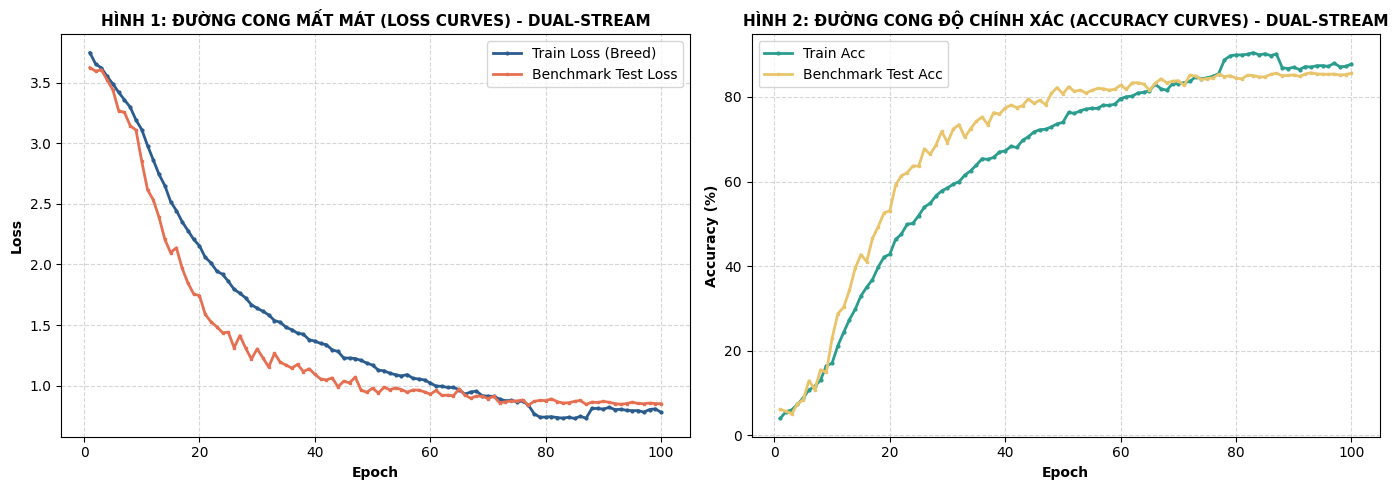

>> Đã lưu biểu đồ huấn luyện: ./plots/dual_stream_curves.png
>> Đã nạp trọng số tối ưu nhất: Epoch 93 (Best Raw Benchmark Acc: 85.72%)

BÁO CÁO KIỂM ĐỊNH HIỆU NĂNG DUAL-STREAM EFFICIENTNET-B0:
- Số mẫu kiểm thử chuẩn (Oxford-IIIT Pet Test): 3,669 ảnh
- Độ chính xác Raw (Single View - Thân + Mặt): 85.72%
- Độ chính xác 4-View Dual-Stream TTA:          86.54%
- Mức cải thiện qua kiểm thử đa góc nhìn (Delta TTA): +0.82%



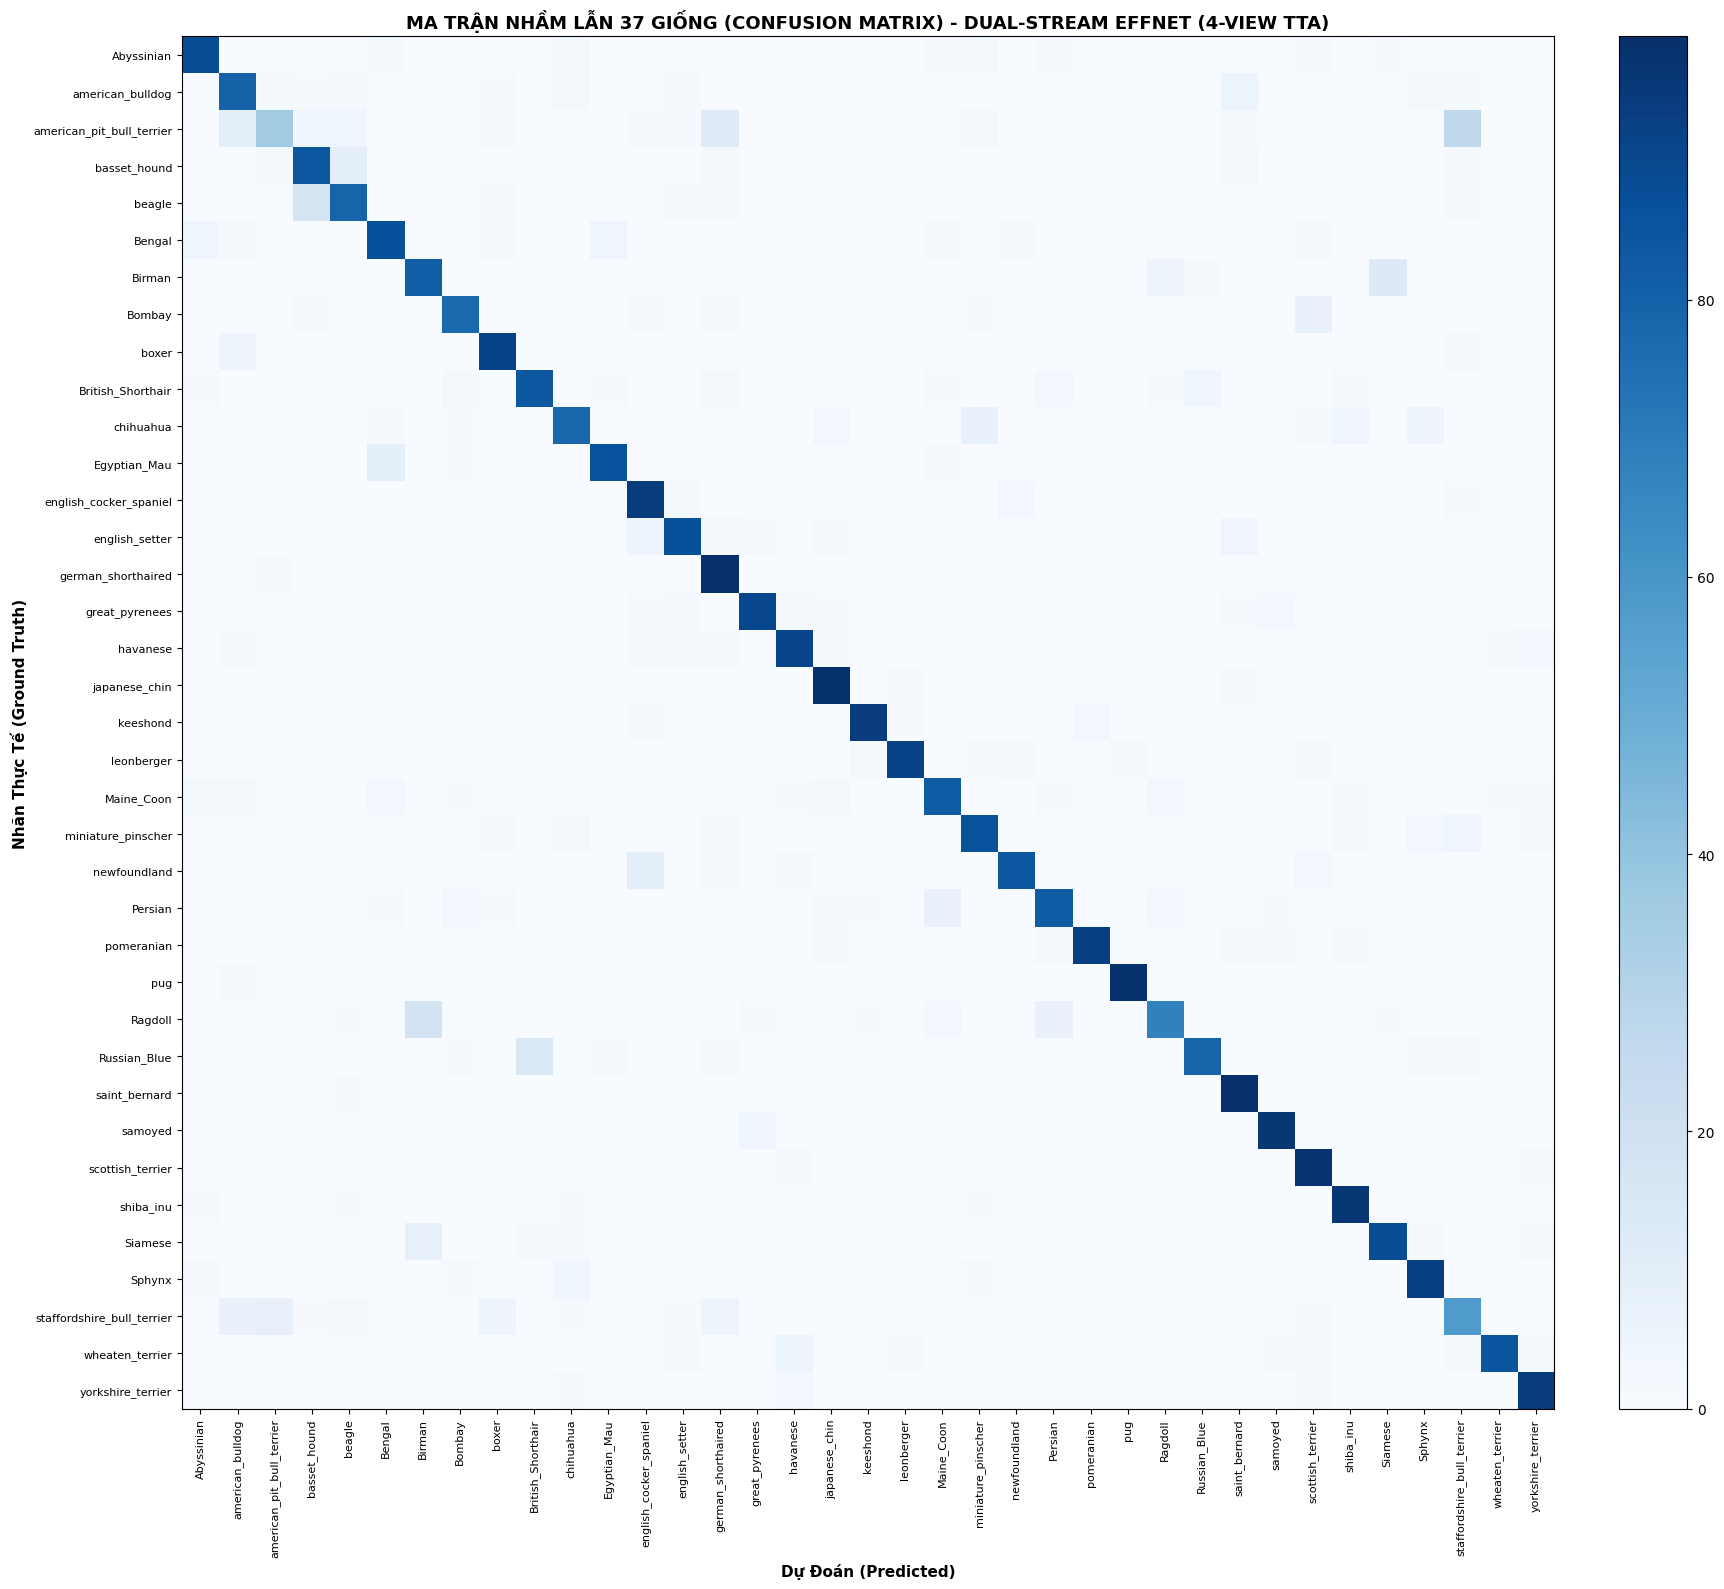

>> Đã lưu Confusion Matrix: ./plots/dual_stream_confusion_matrix.png
>> Đã xuất tệp JSON chỉ số: ./plots/dual_stream_metrics.json


In [7]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader

os.makedirs(args.plots_dir, exist_ok=True)
if "best_ckpt" not in locals():
    best_ckpt = os.path.join(args.checkpoint_dir, "dual_stream_efficientnet_best.pth")
epochs_range = range(1, len(train_losses) + 1)

# 1. Vẽ đường cong Loss & Accuracy theo Epoch
try:
    plt.figure(figsize=(14, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, train_losses, "o-", label="Train Loss (Breed)", color="#2b5c8f", lw=2, markersize=2)
    plt.plot(epochs_range, test_losses, "s-", label="Benchmark Test Loss", color="#e76f51", lw=2, markersize=2)
    plt.title("HÌNH 1: ĐƯỜNG CONG MẤT MÁT (LOSS CURVES) - DUAL-STREAM", fontweight="bold", fontsize=11)
    plt.xlabel("Epoch", fontweight="bold")
    plt.ylabel("Loss", fontweight="bold")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, train_accs, "o-", label="Train Acc", color="#2a9d8f", lw=2, markersize=2)
    plt.plot(epochs_range, test_accs, "s-", label="Benchmark Test Acc", color="#e9c46a", lw=2, markersize=2)
    plt.title("HÌNH 2: ĐƯỜNG CONG ĐỘ CHÍNH XÁC (ACCURACY CURVES) - DUAL-STREAM", fontweight="bold", fontsize=11)
    plt.xlabel("Epoch", fontweight="bold")
    plt.ylabel("Accuracy (%)", fontweight="bold")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()

    plt.tight_layout()
    curves_path = os.path.join(args.plots_dir, "dual_stream_curves.png")
    plt.savefig(curves_path, dpi=300)
    plt.show()
    print(f">> Đã lưu biểu đồ huấn luyện: {curves_path}")
except Exception as e:
    print(f">> Bỏ qua vẽ đường cong huấn luyện: {e}")

# 2. Nạp lại trọng số tối ưu nhất để đánh giá kiểm định TTA
if os.path.exists(best_ckpt):
    best_ckpt_data = torch.load(best_ckpt, map_location=device, weights_only=False)
    model.load_state_dict(best_ckpt_data["model_state_dict"])
    best_epoch_num = best_ckpt_data["epoch"]
    best_raw_acc_val = best_ckpt_data["best_acc"]
    print(f">> Đã nạp trọng số tối ưu nhất: Epoch {best_epoch_num:02d} (Best Raw Benchmark Acc: {best_raw_acc_val:.2f}%)")

model.eval()

# 3. Đánh giá kiểm thử với 4-View Dual-Stream TTA trên Benchmark Oxford Chuẩn (3.669 ảnh)
all_preds_raw, all_preds_tta, all_targets = [], [], []
eval_loader = DataLoader(testset, batch_size=args.batch_size, shuffle=False, num_workers=0)

def zoom_tensor(tensor, zoom_ratio=0.9):
    h, w = tensor.shape[2], tensor.shape[3]
    h_c, w_c = int(h * zoom_ratio), int(w * zoom_ratio)
    top, left = (h - h_c) // 2, (w - w_c) // 2
    crop = tensor[:, :, top:top+h_c, left:left+w_c]
    return F.interpolate(crop, size=(h, w), mode="bilinear", align_corners=False)

with torch.no_grad():
    for (inputs_body, inputs_head), targets, _ in eval_loader:
        inputs_body = inputs_body.to(device)
        inputs_head = inputs_head.to(device)
        targets_np = targets.cpu().numpy()

        # View 1: Ảnh gốc Thân + Mặt
        p1 = F.softmax(model(inputs_body, inputs_head), dim=1)
        preds_raw = p1.max(1)[1].cpu().numpy()

        # View 2: Lật ngang Horizontal Flip
        body_flip = torch.flip(inputs_body, dims=[-1])
        head_flip = torch.flip(inputs_head, dims=[-1])
        p2 = F.softmax(model(body_flip, head_flip), dim=1)

        # View 3: Cắt trọng tâm và phóng to (Zoomed View)
        body_zoom = zoom_tensor(inputs_body, 0.9)
        head_zoom = zoom_tensor(inputs_head, 0.9)
        p3 = F.softmax(model(body_zoom, head_zoom), dim=1)

        # View 4: Phóng to kết hợp lật ngang
        p4 = F.softmax(model(torch.flip(body_zoom, dims=[-1]), torch.flip(head_zoom, dims=[-1])), dim=1)

        # Weighted Ensemble TTA: 40% Gốc + 30% Flip + 15% Zoom + 15% Flip Zoom
        prob_tta = 0.40 * p1 + 0.30 * p2 + 0.15 * p3 + 0.15 * p4
        preds_tta = prob_tta.max(1)[1].cpu().numpy()

        all_preds_raw.extend(preds_raw)
        all_preds_tta.extend(preds_tta)
        all_targets.extend(targets_np)

all_preds_raw = np.array(all_preds_raw)
all_preds_tta = np.array(all_preds_tta)
all_targets = np.array(all_targets)

acc_raw = (all_preds_raw == all_targets).mean() * 100.0
acc_tta = (all_preds_tta == all_targets).mean() * 100.0
gain_tta = acc_tta - acc_raw

print(f"\n==================================================================")
print(f"BÁO CÁO KIỂM ĐỊNH HIỆU NĂNG DUAL-STREAM EFFICIENTNET-B0:")
print(f"- Số mẫu kiểm thử chuẩn (Oxford-IIIT Pet Test): {len(all_targets):,} ảnh")
print(f"- Độ chính xác Raw (Single View - Thân + Mặt): {acc_raw:.2f}%")
print(f"- Độ chính xác 4-View Dual-Stream TTA:          {acc_tta:.2f}%")
print(f"- Mức cải thiện qua kiểm thử đa góc nhìn (Delta TTA): +{gain_tta:.2f}%")
print(f"==================================================================\n")

# 4. Vẽ Confusion Matrix chuẩn 37x37
try:
    if "classes" not in locals() or classes is None:
        if hasattr(testset, "class_names"):
            classes = testset.class_names
        else:
            classes = [f"Class_{c}" for c in range(37)]
    cm = confusion_matrix(all_targets, all_preds_tta)
    plt.figure(figsize=(18, 16))
    plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
    plt.title("MA TRẬN NHẦM LẪN 37 GIỐNG (CONFUSION MATRIX) - DUAL-STREAM EFFNET (4-VIEW TTA)", fontweight="bold", fontsize=13)
    plt.colorbar(fraction=0.046, pad=0.04)

    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=90, fontsize=8)
    plt.yticks(tick_marks, classes, fontsize=8)

    plt.ylabel("Nhãn Thực Tế (Ground Truth)", fontweight="bold", fontsize=11)
    plt.xlabel("Dự Đoán (Predicted)", fontweight="bold", fontsize=11)
    plt.tight_layout()

    cm_path = os.path.join(args.plots_dir, "dual_stream_confusion_matrix.png")
    plt.savefig(cm_path, dpi=300)
    plt.show()
    print(f">> Đã lưu Confusion Matrix: {cm_path}")
except Exception as e:
    print(f">> Bỏ qua lưu Confusion Matrix: {e}")

# 5. Lưu kết quả JSON để đối sánh Benchmark tổng hợp
metrics = {
    "model_name": "Dual-Stream EfficientNet-B0 (Face + Body Zoom - From Scratch/Hybrid)",
    "total_params": total_params,
    "img_size": args.img_size,
    "batch_size": args.batch_size,
    "epochs_trained": len(train_losses),
    "train_samples": len(trainset),
    "test_samples": len(testset),
    "best_epoch": best_epoch_num if "best_epoch_num" in locals() else len(train_losses),
    "final_train_loss": round(train_losses[-1], 3) if train_losses else None,
    "final_train_acc": round(train_accs[-1], 2) if train_accs else None,
    "final_test_loss": round(test_losses[-1], 3) if test_losses else None,
    "final_test_acc": round(test_accs[-1], 2) if test_accs else None,
    "best_benchmark_test_acc_raw": round(acc_raw, 2),
    "best_benchmark_test_acc_tta": round(acc_tta, 2),
    "delta_tta_gain": round(gain_tta, 2)
}

metrics_path = os.path.join(args.plots_dir, "dual_stream_metrics.json")
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)
print(f">> Đã xuất tệp JSON chỉ số: {metrics_path}")
